# Suspended Sediment Particle Size Prediction

Step-by-step comparison of Random Forest, SVR, and XGBoost for predicting `d50` and `sigma2` from the supplied synthetic dataset.

**Evaluation safeguards:** incomplete rows are removed, then data are split into training and test sets before feature selection or model fitting. No rows are removed using target values. This avoids using held-out target labels to decide which observations are retained. The data are synthetic, and the random split measures performance on similar rows from this generated dataset rather than future field samples.

In [1]:
# Step 1: Imports and load the supplied dataset
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

DATA_PATH = Path("data/synthetic_data_improved.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/synthetic_data_improved.csv")
data = pd.read_csv(DATA_PATH)
print("Original dataset shape:", data.shape)

# The time column is an index, not a predictor. Retain all target values.
data = data.drop(columns=["time"], errors="ignore").dropna().reset_index(drop=True)
features = ["S", "ub", "np", "T", "a676_a650", "a450_a676", "chl_a", "u"]
targets = ["d50", "sigma2"]
X = data[features]
y = data[targets]
print("Complete rows retained:", len(data))
print("Predictor columns:", features)
print("Target columns:", targets)

Original dataset shape: (1648, 11)
Complete rows retained: 1402
Predictor columns: ['S', 'ub', 'np', 'T', 'a676_a650', 'a450_a676', 'chl_a', 'u']
Target columns: ['d50', 'sigma2']


In [2]:
# Step 2: Split before feature selection and model fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Split: 70/30 shuffled holdout; random_state=42")

Training rows: 981
Test rows: 421
Split: 70/30 shuffled holdout; random_state=42


In [3]:
# Step 3: Feature importance uses training data only
importance_model = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)
importance_model.fit(X_train, y_train["d50"])
importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)
display(importance)

top_features = importance.head(4)["Feature"].tolist()
print("Selected top four training-only features:", top_features)
X_train_selected = X_train[top_features]
X_test_selected = X_test[top_features]

,Feature,Importance
0,ub,0.453915
1,S,0.253005
2,chl_a,0.136966
3,T,0.056232
4,a676_a650,0.034421
5,a450_a676,0.029848
6,u,0.019154
7,np,0.016459


Selected top four training-only features: ['ub', 'S', 'chl_a', 'T']


In [4]:
# Step 4: Random Forest regression
rf_models = {}
for target in targets:
    model = RandomForestRegressor(
        n_estimators=400, max_depth=None, min_samples_split=2,
        min_samples_leaf=1, random_state=42, oob_score=True, n_jobs=-1
    )
    model.fit(X_train_selected, y_train[target])
    rf_models[target] = model
    prediction = model.predict(X_test_selected)
    print(f"{target}: test R²={r2_score(y_test[target], prediction):.6f}; "
          f"OOB R²={model.oob_score_:.6f}")

d50: test R²=0.511284; OOB R²=0.595742


sigma2: test R²=0.795068; OOB R²=0.728415


In [5]:
# Step 5: Standardized SVR with five-fold grid search
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])
parameter_grid = {
    "svr__C": [1, 10, 100, 500, 1000, 2000],
    "svr__epsilon": [0.1, 0.5, 1, 2]
}
svr_models = {}
for target in targets:
    search = GridSearchCV(
        svr_pipeline, parameter_grid, scoring="r2", cv=5, n_jobs=1
    )
    search.fit(X_train_selected, y_train[target])
    svr_models[target] = search.best_estimator_
    prediction = search.predict(X_test_selected)
    print(f"{target}: best parameters={search.best_params_}; "
          f"test R²={r2_score(y_test[target], prediction):.6f}")

d50: best parameters={'svr__C': 100, 'svr__epsilon': 0.5}; test R²=0.553691


sigma2: best parameters={'svr__C': 100, 'svr__epsilon': 0.1}; test R²=0.803180


In [6]:
# Step 6: XGBoost regression
xgb_parameters = {
    "n_estimators": 300,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": 1
}
xgb_models = {}
for target in targets:
    model = XGBRegressor(**xgb_parameters)
    model.fit(X_train_selected, y_train[target])
    xgb_models[target] = model
    prediction = model.predict(X_test_selected)
    print(f"{target}: test R²={r2_score(y_test[target], prediction):.6f}")

d50: test R²=0.427198


sigma2: test R²=0.744005


In [7]:
# Step 7: Final model comparison table: R², RMSE, and MAE
model_groups = {
    "Random Forest": rf_models,
    "SVR": svr_models,
    "XGBoost": xgb_models
}
rows = []
predictions = {}
for model_name, fitted_models in model_groups.items():
    for target in targets:
        predicted = fitted_models[target].predict(X_test_selected)
        predictions[(model_name, target)] = predicted
        rows.append({
            "Model": model_name,
            "Target": target,
            "R²": r2_score(y_test[target], predicted),
            "RMSE": np.sqrt(mean_squared_error(y_test[target], predicted)),
            "MAE": mean_absolute_error(y_test[target], predicted)
        })
comparison = pd.DataFrame(rows).round(6)
display(comparison)

,Model,Target,R²,RMSE,MAE
0,Random Forest,d50,0.511284,38.424357,15.833124
1,Random Forest,sigma2,0.795068,13.463226,6.993235
2,SVR,d50,0.553691,36.719457,13.912968
3,SVR,sigma2,0.803180,13.194082,6.253565
4,XGBoost,d50,0.427198,41.598798,16.448039
5,XGBoost,sigma2,0.744005,15.047352,7.616675


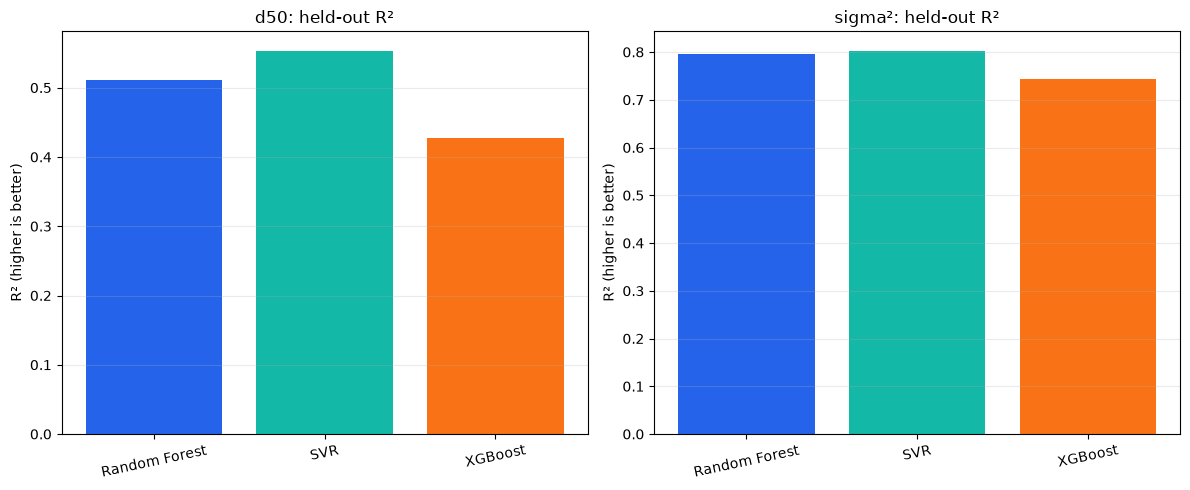

In [8]:
# Step 8: Visual comparison of held-out R² scores
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target, label in zip(axes, targets, ["d50", "sigma²"]):
    subset = comparison[comparison["Target"] == target]
    ax.bar(subset["Model"], subset["R²"], color=["#2563eb", "#14b8a6", "#f97316"])
    ax.set_title(f"{label}: held-out R²")
    ax.set_ylabel("R² (higher is better)")
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()